In [1]:
from google.colab import files
uploaded=files.upload()

Saving netflix_titles.csv to netflix_titles.csv


In [2]:
import pandas as pd
import numpy as np
df=pd.read_csv("netflix_titles.csv")
print("Data loaded successfully")
print(df.shape)
df.head()

Data loaded successfully
(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


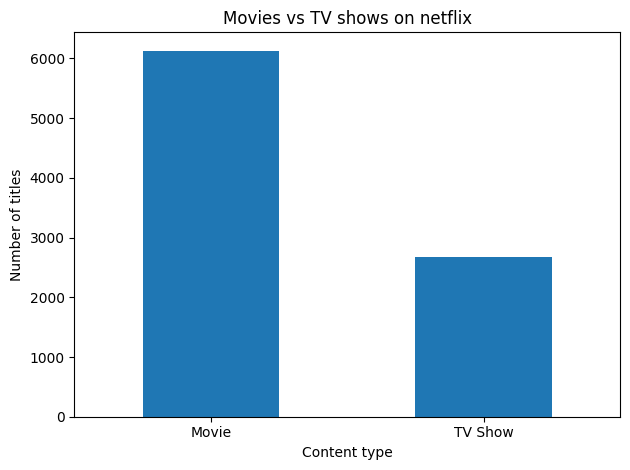

In [3]:
import matplotlib.pyplot as plt
type_counts=df["type"].value_counts()
type_counts.plot(kind="bar")
plt.title("Movies vs TV shows on netflix")
plt.xlabel("Content type")
plt.ylabel("Number of titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
missing_values=df.isnull().sum()
print(missing_values)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [5]:
missing_percent=(df.isnull().sum()/len(df))*100
missing_summary=pd.DataFrame({
    "Missing count": df.isnull().sum(),
    "Missing Percentage":missing_percent.round(2)
})
missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False

)

,Missing count,Missing Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


In [6]:
df_clean=df.copy()
df_clean=df_clean.drop_duplicates()
text_columns=["director","cast","country","rating","duration","listed_in","description"]
for column in text_columns:
  df_clean[column]=df_clean[column].fillna("")
print("Original rows",len(df))
print("Cleaned rows",len(df_clean))

print("\nRemaining missing values: ",df_clean[text_columns].isnull().sum())

Original rows 8807
Cleaned rows 8807

Remaining missing values:  director       0
cast           0
country        0
rating         0
duration       0
listed_in      0
description    0
dtype: int64


In [7]:
df_clean.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,,,,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


In [8]:
features=["type","director","cast","country","listed_in","description"]
df_clean[features].head()

,type,director,cast,country,listed_in,description
0,Movie,Kirsten Johnson,,United States,Documentaries,"As her father nears the end of his life, filmm..."
1,TV Show,,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,TV Show,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,TV Show,,,,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,TV Show,,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
def create_content_profile(row):
  return " ".join([
      str(row["type"]),
      str(row["director"]),
      str(row["cast"]),
      str(row["country"]),
      str(row["listed_in"]),
      str(row["description"])
])
df_clean["content_profile"]=df_clean.apply(
    create_content_profile,
    axis=1
)
df_clean[["title","content_profile"]].head(3)

,title,content_profile
0,Dick Johnson Is Dead,Movie Kirsten Johnson United States Documenta...
1,Blood & Water,"TV Show Ama Qamata, Khosi Ngema, Gail Mabalan..."
2,Ganglands,"TV Show Julien Leclercq Sami Bouajila, Tracy G..."


In [10]:
df_clean["content_profile"]=(
    df_clean["content_profile"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+"," ",regex=True)
    .str.strip()
)
print(df_clean["content_profile"].iloc[0])

movie kirsten johnson united states documentaries as her father nears the end of his life, filmmaker kirsten johnson stages his death in inventive and comical ways to help them both face the inevitable.


In [11]:
print("Total titles:",len(df_clean))
print("Content_profile:",df_clean["content_profile"].notna().sum())
print("\nExample content profile")
for _,row in df_clean[["title","content_profile"]].head(5).iterrows():
  print(f"\nTitle:{row['title']}")
  print(f"Profile:{row['content_profile'][:250]}...")

Total titles: 8807
Content_profile: 8807

Example content profile

Title:Dick Johnson Is Dead
Profile:movie kirsten johnson united states documentaries as her father nears the end of his life, filmmaker kirsten johnson stages his death in inventive and comical ways to help them both face the inevitable....

Title:Blood & Water
Profile:tv show ama qamata, khosi ngema, gail mabalane, thabang molaba, dillon windvogel, natasha thahane, arno greeff, xolile tshabalala, getmore sithole, cindy mahlangu, ryle de morny, greteli fincham, sello maake ka-ncube, odwa gwanya, mekaila mathys, san...

Title:Ganglands
Profile:tv show julien leclercq sami bouajila, tracy gotoas, samuel jouy, nabiha akkari, sofia lesaffre, salim kechiouche, noureddine farihi, geert van rampelberg, bakary diombera crime tv shows, international tv shows, tv action & adventure to protect his f...

Title:Jailbirds New Orleans
Profile:tv show docuseries, reality tv feuds, flirtations and toilet talk go down among the incarcera

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer(
    stop_words="english",
    max_features=10000
)
tfidf_matrix=tfidf.fit_transform(
    df_clean["content_profile"]
)
print("TF-IDF matrix shape: ",tfidf_matrix.shape)
print("Number of titles: ",tfidf_matrix.shape[0])
print("Number of features: ",tfidf_matrix.shape[1])


TF-IDF matrix shape:  (8807, 10000)
Number of titles:  8807
Number of features:  10000


In [13]:

# Display some terms learned by TF-IDF
feature_names = tfidf.get_feature_names_out()

print("First 30 vocabulary terms:")
print(feature_names[:30])

# Inspect the nonzero weights for the first title
first_vector = tfidf_matrix[0]

print("\nNonzero TF-IDF values:")
print(first_vector)


First 30 vocabulary terms:
['000' '10' '100' '11' '12' '13' '14' '15' '16' '17' '18' '18th' '19'
 '1920s' '1930s' '1950s' '1960s' '1970s' '1971' '1980' '1980s' '1989'
 '1990s' '1992' '1994' '1996' '19th' '20' '2011' '2012']

Nonzero TF-IDF values:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 18 stored elements and shape (1, 10000)>
  Coords	Values
  (0, 6062)	0.04754979020973245
  (0, 4938)	0.5151059353356725
  (0, 4625)	0.3710486357791631
  (0, 9344)	0.060418204983941654
  (0, 8525)	0.0652556190181098
  (0, 2475)	0.11567924670920819
  (0, 3048)	0.15134713117976006
  (0, 6249)	0.2841674361694091
  (0, 2798)	0.2085653753036842
  (0, 5223)	0.11723517442737397
  (0, 3130)	0.21347459623578016
  (0, 8498)	0.2599622474322194
  (0, 2186)	0.16907448675543768
  (0, 4352)	0.28955048670157846
  (0, 1798)	0.28955048670157846
  (0, 9649)	0.2115518699578399
  (0, 3885)	0.153290847243603
  (0, 2980)	0.18672859949677537


In [14]:
from sklearn.metrics.pairwise import cosine_similarity
first_vector=tfidf_matrix[0]
similarity_scores=cosine_similarity(
    first_vector,
    tfidf_matrix
).flatten()

print("Number of similarity scores:", len(similarity_scores))
print("First 10 scores:", similarity_scores[:10])

Number of similarity scores: 8807
First 10 scores: [1.         0.         0.         0.         0.01208417 0.
 0.00171715 0.01347274 0.03585032 0.01811072]


In [15]:
title_index=0
ranked_scores=list(enumerate(similarity_scores))
ranked_scores=sorted(
    ranked_scores,
    key=lambda x:x[1],
    reverse=True
)
ranked_scores=[
    item for item in ranked_scores
    if item[0]!=title_index
]
top_10=ranked_scores[:10]
for index,score in top_10:
  print(df_clean.iloc[index]["title"]," | Similarity: ",round(score,3))

Woodshock  | Similarity:  0.179
How to Be a Player  | Similarity:  0.172
Midnight Special  | Similarity:  0.146
Daffedar  | Similarity:  0.14
Barbie Dreamhouse Adventures  | Similarity:  0.136
New Girl  | Similarity:  0.135
The Death and Life of Marsha P. Johnson  | Similarity:  0.134
Extremis  | Similarity:  0.13
Barbie & Chelsea: The Lost Birthday  | Similarity:  0.125
A Gray State  | Similarity:  0.124


In [16]:

def recommend_movies(title, top_n=5):
    if not isinstance(title, str):
        raise TypeError("Please enter a title as a string.")

    query = title.strip().lower()

    # Match the title and get its row position
    title_values = (
        df_clean["title"]
        .fillna("")
        .str.strip()
        .str.lower()
    )

    matches = (title_values == query).to_numpy()
    positions = matches.nonzero()[0]

    if len(positions) == 0:
        print(f"Title '{title}' not found.")
        return pd.DataFrame()

    # Use the row position, not the DataFrame index label
    position = positions[0]

    # Compare this title with all title vectors
    scores = cosine_similarity(
        tfidf_matrix[position],
        tfidf_matrix
    ).ravel()

    # Exclude the selected row and rank the rest
    ranked = scores.argsort()[::-1]
    ranked = ranked[ranked != position]
    top_indices = ranked[:top_n]

    result = df_clean.iloc[top_indices][
        ["title", "type", "listed_in", "description"]
    ].copy()

    result["similarity_score"] = scores[top_indices]

    return result.reset_index(drop=True)


In [17]:
recommendations = recommend_movies("Dark")
display(recommendations)


,title,type,listed_in,description,similarity_score
0,A Perfect Crime,TV Show,"Crime TV Shows, Docuseries, International TV S...",This docuseries investigates the 1991 killing ...,0.220302
1,Diamond City,TV Show,"Crime TV Shows, International TV Shows, TV Dramas",A prominent prosecuting attorney must defend h...,0.197397
2,Three Wives One Husband,TV Show,"British TV Shows, International TV Shows, Real...",A film crew captures a year in the life of mod...,0.192943
3,The Defeated,TV Show,"Crime TV Shows, International TV Shows, TV Dramas","In 1946 Berlin, an American cop searches for h...",0.190068
4,Everyday Miracles,TV Show,"British TV Shows, Docuseries, International TV...",Materials scientist Mark Miodownik takes us in...,0.189693


In [18]:

test_titles = [
    "Stranger Things",
    "The Crown",
    "Breaking Bad",
    "Our Planet"
]

for title in test_titles:
    print(f"\n{'=' * 50}")
    print(f"Recommendations for: {title}")
    print("=" * 50)

    results = recommend_movies(title, top_n=5)

    if not results.empty:
        display(
            results[
                ["title", "type", "listed_in", "similarity_score"]
            ]
        )



Recommendations for: Stranger Things


,title,type,listed_in,similarity_score
0,Beyond Stranger Things,TV Show,"Stand-Up Comedy & Talk Shows, TV Mysteries, TV...",0.519920
1,Warrior Nun,TV Show,"TV Action & Adventure, TV Mysteries, TV Sci-Fi...",0.157321
2,Good Witch,TV Show,"TV Dramas, TV Sci-Fi & Fantasy",0.157080
3,Anjaan: Special Crimes Unit,TV Show,"International TV Shows, TV Horror, TV Mysteries",0.156651
4,Kiss Me First,TV Show,"British TV Shows, Crime TV Shows, Internationa...",0.155428



Recommendations for: The Crown


,title,type,listed_in,similarity_score
0,Age Gap Love,TV Show,"British TV Shows, Reality TV, Romantic TV Shows",0.178369
1,Flowers,TV Show,"British TV Shows, International TV Shows, TV C...",0.176197
2,Downton Abbey,TV Show,"British TV Shows, International TV Shows, TV D...",0.172627
3,Call the Midwife,TV Show,"British TV Shows, International TV Shows, TV D...",0.170275
4,Stories by Rabindranath Tagore,TV Show,"International TV Shows, TV Dramas",0.168017



Recommendations for: Breaking Bad


,title,type,listed_in,similarity_score
0,Better Call Saul,TV Show,"Crime TV Shows, TV Comedies, TV Dramas",0.303291
1,Hormones,TV Show,"International TV Shows, Romantic TV Shows, TV ...",0.184997
2,The Show,Movie,Dramas,0.175947
3,"Have You Ever Fallen in Love, Miss Jiang?",TV Show,"Crime TV Shows, International TV Shows, TV Dramas",0.170839
4,The Underclass,TV Show,"International TV Shows, TV Dramas, Teen TV Shows",0.168662



Recommendations for: Our Planet


,title,type,listed_in,similarity_score
0,Planet Earth II,TV Show,"British TV Shows, Docuseries, Science & Nature TV",0.399371
1,Nature's Great Events: Diaries,TV Show,"British TV Shows, Docuseries, Science & Nature TV",0.367213
2,Life Story,TV Show,"British TV Shows, Docuseries, Science & Nature TV",0.356718
3,Blue Planet II,TV Show,"British TV Shows, Docuseries, Science & Nature TV",0.355427
4,Moving Art,TV Show,"Docuseries, Science & Nature TV",0.327525


In [19]:

def genre_precision_at_k(title, k=5):
    # Get recommendations
    results = recommend_movies(title, top_n=k)

    if results.empty:
        return None

    # Find the source title
    source = df_clean[
        df_clean["title"].fillna("").str.strip().str.lower()
        == title.strip().lower()
    ]

    if source.empty:
        return None

    source_genres = set(
        str(source.iloc[0]["listed_in"]).lower().split(", ")
    )
    source_genres.discard("")

    if not source_genres:
        return None

    relevant_count = 0

    for genres in results["listed_in"]:
        recommended_genres = set(
            str(genres).lower().split(", ")
        )
        recommended_genres.discard("")

        if source_genres & recommended_genres:
            relevant_count += 1

    return relevant_count / len(results)


score = genre_precision_at_k("Stranger Things", k=5)

print("Genre Precision@5:", score)


Genre Precision@5: 0.8


In [20]:

evaluation_titles = [
    "Stranger Things",
    "The Crown",
    "Breaking Bad",
    "Our Planet"
]

scores = []

for title in evaluation_titles:
    score = genre_precision_at_k(title, k=5)

    if score is not None:
        scores.append({
            "title": title,
            "genre_precision_at_5": score
        })

evaluation_df = pd.DataFrame(scores)

display(evaluation_df)

if not evaluation_df.empty:
    print(
        "Average Genre Precision@5:",
        round(evaluation_df["genre_precision_at_5"].mean(), 3)
    )


,title,genre_precision_at_5
0,Stranger Things,0.8
1,The Crown,1.0
2,Breaking Bad,0.8
3,Our Planet,1.0


Average Genre Precision@5: 0.9


In [21]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import hstack
import numpy as np

# Features and their initial weights
feature_weights = {
    "listed_in": 0.35,
    "description": 0.30,
    "cast": 0.15,
    "director": 0.10,
    "type": 0.05,
    "country": 0.05
}

# Keep all feature matrices in the same row order
feature_matrices = {}
feature_vectorizers = {}

for column, weight in feature_weights.items():
    text = (
        df_clean[column]
        .fillna("")
        .astype(str)
        .str.lower()
        .str.strip()
    )

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=10000
    )

    matrix = vectorizer.fit_transform(text)

    # Scale this feature's contribution
    weighted_matrix_part = matrix * np.sqrt(weight)

    feature_matrices[column] = weighted_matrix_part
    feature_vectorizers[column] = vectorizer

# Combine all weighted feature matrices
improved_matrix = hstack(
    [feature_matrices[col] for col in feature_weights],
    format="csr"
)

print("Improved matrix shape:", improved_matrix.shape)
print("Number of titles:", len(df_clean))


Improved matrix shape: (8807, 26607)
Number of titles: 8807


In [22]:

# Preserve the current working baseline function
recommend_movies_baseline = recommend_movies


In [23]:

def recommend_movies_improved(title, top_n=5):
    if not isinstance(title, str):
        raise TypeError("Please enter a title as a string.")

    query = title.strip().lower()

    title_values = (
        df_clean["title"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    positions = (title_values == query).to_numpy().nonzero()[0]

    if len(positions) == 0:
        print(f"Title '{title}' not found.")
        return pd.DataFrame()

    position = positions[0]

    scores = cosine_similarity(
        improved_matrix[position],
        improved_matrix
    ).ravel()

    ranked = scores.argsort()[::-1]
    ranked = ranked[ranked != position]
    top_indices = ranked[:top_n]

    results = df_clean.iloc[top_indices][
        ["title", "type", "listed_in", "description"]
    ].copy()

    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)


In [29]:

test_title = "Breaking bad"

print("BASELINE MODEL")
display(
    recommend_movies_baseline(test_title, top_n=5)
    [["title", "listed_in", "similarity_score"]]
)

print("IMPROVED MODEL")
display(
    recommend_movies_improved(test_title, top_n=5)
    [["title", "listed_in", "similarity_score"]]
)


BASELINE MODEL


,title,listed_in,similarity_score
0,Better Call Saul,"Crime TV Shows, TV Comedies, TV Dramas",0.303291
1,Hormones,"International TV Shows, Romantic TV Shows, TV ...",0.184997
2,The Show,Dramas,0.175947
3,"Have You Ever Fallen in Love, Miss Jiang?","Crime TV Shows, International TV Shows, TV Dramas",0.170839
4,The Underclass,"International TV Shows, TV Dramas, Teen TV Shows",0.168662


IMPROVED MODEL


,title,listed_in,similarity_score
0,Better Call Saul,"Crime TV Shows, TV Comedies, TV Dramas",0.524670
1,Dare Me,"Crime TV Shows, TV Dramas, TV Thrillers",0.521985
2,Ozark,"Crime TV Shows, TV Dramas, TV Thrillers",0.507353
3,The Blacklist,"Crime TV Shows, TV Dramas, TV Thrillers",0.500000
4,Designated Survivor,"Crime TV Shows, TV Dramas, TV Thrillers",0.500000


In [26]:
from google.colab import output

output.enable_custom_widget_manager()


In [34]:

import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import output

output.enable_custom_widget_manager()

available_titles = sorted(
    df_clean["title"].dropna().astype(str).unique().tolist()
)

# Search input
title_input = widgets.Text(
    placeholder="Type a Netflix title...",
    description="Search:",
    layout=widgets.Layout(width="90%")
)

search_button = widgets.Button(
    description="Find Title",
    button_style="info"
)

# Matching titles appear here
title_dropdown = widgets.Dropdown(
    options=[],
    description="Select:",
    layout=widgets.Layout(width="90%")
)

number_slider = widgets.IntSlider(
    value=5,
    min=3,
    max=15,
    description="Results:",
    continuous_update=False
)

model_dropdown = widgets.Dropdown(
    options=[
        ("Improved model", "improved"),
        ("Baseline model", "baseline")
    ],
    value="improved",
    description="Model:"
)

recommend_button = widgets.Button(
    description="Get Recommendations",
    button_style="danger"
)

search_output = widgets.Output()
recommendation_output = widgets.Output()


# Search for matching titles without removing the UI
def search_titles(button):
    query = title_input.value.strip().lower()

    with search_output:
        clear_output(wait=True)

        if not query:
            title_dropdown.options = []
            print("Type a title first.")
            return

        matches = [
            title for title in available_titles
            if query in title.lower()
        ]

        if not matches:
            title_dropdown.options = []
            print("No matching titles found.")
            return

        title_dropdown.options = matches
        title_dropdown.value = matches[0]

        print(f"Found {len(matches)} matching titles.")
        print("Choose the title from the dropdown.")


# Generate recommendations without clearing the whole UI
def show_recommendations(button):
    with recommendation_output:
        clear_output(wait=True)

        selected_title = title_dropdown.value

        if not selected_title:
            print("Search for and select a title first.")
            return

        if model_dropdown.value == "improved":
            results = recommend_movies_improved(
                selected_title,
                top_n=number_slider.value
            )
        else:
            results = recommend_movies_baseline(
                selected_title,
                top_n=number_slider.value
            )

        if results.empty:
            print("No recommendations found.")
            return

        print(f"Recommendations for: {selected_title}")

        display(
            results[
                [
                    "title",
                    "type",
                    "listed_in",
                    "description",
                    "similarity_score"
                ]
            ].style.format(
                {"similarity_score": "{:.3f}"}
            )
        )


search_button.on_click(search_titles)
recommend_button.on_click(show_recommendations)

# Display the complete UI once
display(widgets.VBox([
    widgets.HTML(
        "<h2>Netflix Content Recommendation System</h2>"
        "<p>Search, select, and discover similar titles.</p>"
    ),
    title_input,
    search_button,
    search_output,
    title_dropdown,
    number_slider,
    model_dropdown,
    recommend_button,
    recommendation_output
]))
